# Lake Pontchartrain Delft3d_FM Model Post-Processing - 2D

Quick review of spatial model output from `FlowFM_map.nc`.

## Notebook Contents
- Check time range and available variables
- Make map figures for key fields
- Make a single-variable movie (selectable variable)
- Optionally export a smaller NetCDF for collaborators

## Notes
- The movie/export steps can take a while depending on timestep range.
- Output files are written under the project `outputs` folder.

## 1. Setup

Imports and basic setup used by the cells below.

In [1]:
import os
from matplotlib import pyplot as plt
import xarray as xr
import pandas as pd
import cmocean
import dfm_tools as dfmt
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

## 2. Load Model Output

Set paths, open model output, and inspect available variables.

In [ ]:
# Model output paths
MAP_PATH = Path(r"C:\Users\hydro\BCS_Paper\WL_Lake_Pontchartrain_Model_2014.dsproj_data\FlowFM\output\FlowFM_map.nc")

# Analysis window (removes runup)
start_time = pd.Timestamp("2014-01-01 00:00")
end_time   = pd.Timestamp("2014-12-31 23:00")

file_location = MAP_PATH

file_nc = os.path.join(file_location)
uds_map = dfmt.open_partitioned_dataset(file_nc)

# Variable info (names, units, coordinates, dtypes, etc.) for quick inspection.
map_vars_pd = dfmt.get_ncvarproperties(uds_map)

>> xu.open_dataset() with 1 partition(s): 1 [nodomainvar] : 0.37 sec


## 3. Spatial Plots

Create map plots for selected variables and timesteps.

- Four-variable subplot
- Single-variable plot

#### Colormaps (cmocean)
This notebook uses `cmocean` colormaps because they are designed for ocean and geospatial data and are easier to interpret than default palettes.

A few used here:
- `amp` for velocity magnitude
- `deep` for water level
- `thermal` for temperature
- `haline` for salinity

See the full colormap gallery: https://matplotlib.org/cmocean/

### Format Timesteps
Convert timesteps to readable strings for plot titles.

In [3]:
# Use in-memory dataset directly (uds_map is already loaded from FlowFM_map.nc).
ds_selected = uds_map.obj if hasattr(uds_map, "obj") else uds_map

time_str_all = ds_selected.time.dt.strftime("%m-%d-%Y %H:%M:%S")
t_start = time_str_all.isel(time=0).item()
t_end = time_str_all.isel(time=-1).item()
n_timesteps = ds_selected.sizes["time"]

dataset_label = file_location.name if hasattr(file_location, "name") else str(file_location)
print("\nDataset:", dataset_label)
print("Time range:", t_start, "to", t_end)
print("Timesteps:", n_timesteps)


Dataset: FlowFM_map.nc
Time range: 01-01-2014 00:00:00 to 12-31-2014 00:00:00
Timesteps: 8737


### 3.1 Four-Panel Preview

Plot velocity, water level, temperature, and salinity for one timestep.

Plot timestamp: 01-01-2014 12:00:00


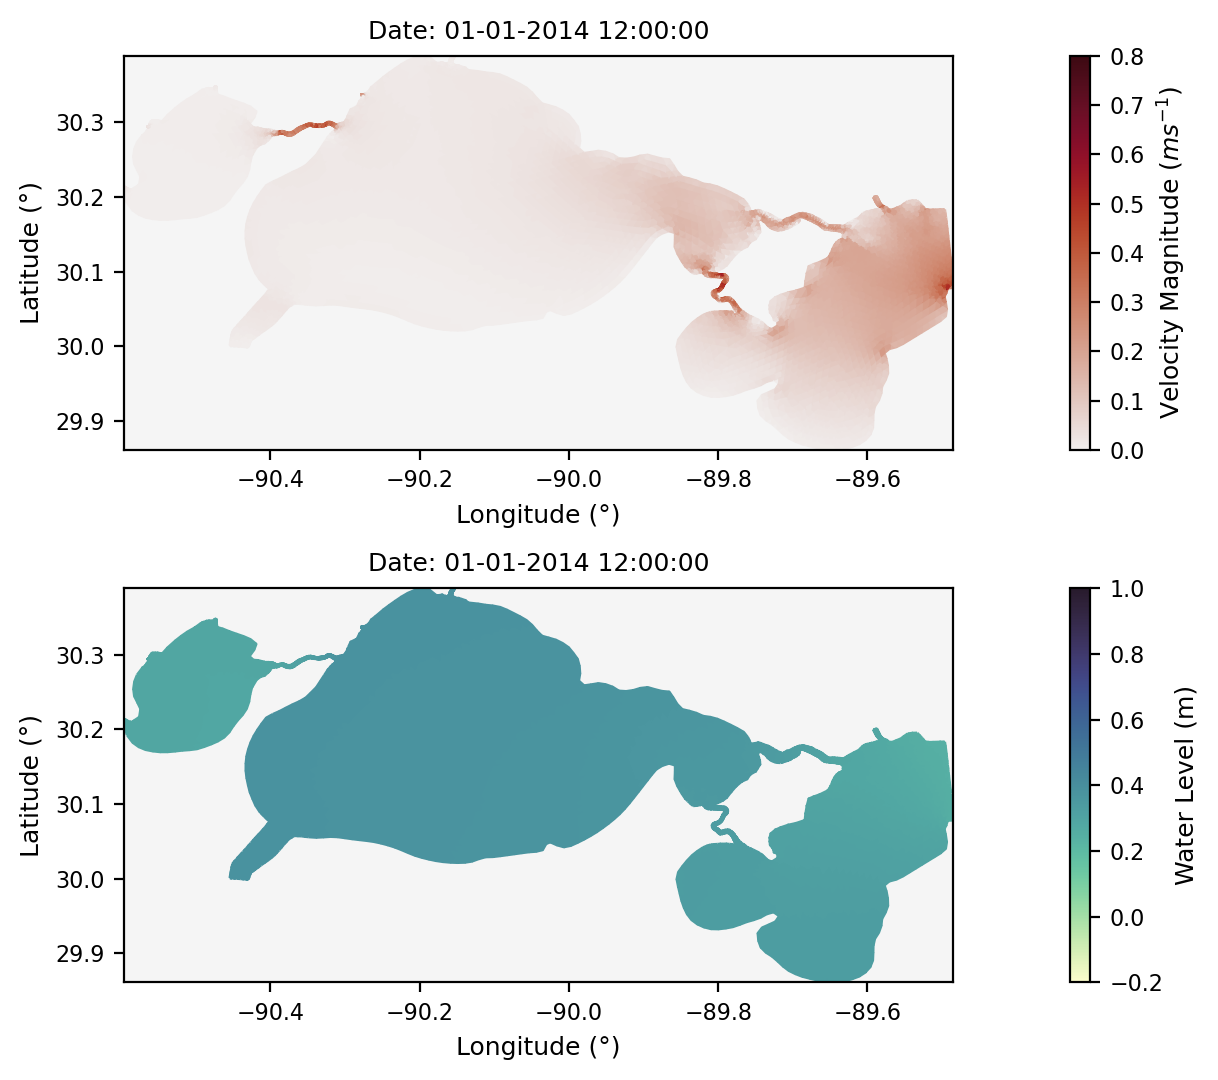

In [4]:
# Choose the timestep to preview.
preview_timestep = 12
t_str = time_str_all.isel(time=preview_timestep).item()
print("Plot timestamp:", t_str)


# Set Plot specifications for each variable you want to see
plot_specs = [
    ("mesh2d_ucmag", "Velocity Magnitude $(m s^{-1})$", cmocean.cm.amp, 0.0, 0.8),
    ("mesh2d_s1", "Water Level (m)", cmocean.cm.deep, -0.20, 1.0),
    # ("mesh2d_tem1", "Temperature (°C)", cmocean.cm.thermal, 24.0, 34.0),
    # ("mesh2d_sa1", "Salinity (PSU)", cmocean.cm.haline, 0.0, 18.0),
]

# Font-size controls
title_fontsize = 9
axis_label_fontsize = 9
tick_fontsize = 8
cbar_label_fontsize = 9
cbar_tick_fontsize = 8

# Create Figure
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), dpi=200)
axes = axes.ravel()
for ax, (var_name, common_name, cmap, vmin, vmax) in zip(axes, plot_specs):
    quad = uds_map[var_name].isel(time=preview_timestep).ugrid.plot(
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=True,
        cbar_kwargs={"label": common_name},
    )
    cbar = quad.colorbar
    cbar.set_label(common_name, fontsize=cbar_label_fontsize)
    cbar.ax.tick_params(labelsize=cbar_tick_fontsize)

    ax.set_aspect("equal")
    ax.set_title(f"Date: {t_str}", fontsize=title_fontsize)
    ax.set_xlabel("Longitude (°)", fontsize=axis_label_fontsize)
    ax.set_ylabel("Latitude (°)", fontsize=axis_label_fontsize)
    ax.set_aspect('equal')
    ax.set_facecolor('whitesmoke')
    ax.tick_params(labelsize=tick_fontsize)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()


### 3.2 Single-Variable Plot

Plot one variable at one timestep.

Plot timestamp: 01-01-2014 12:00:00


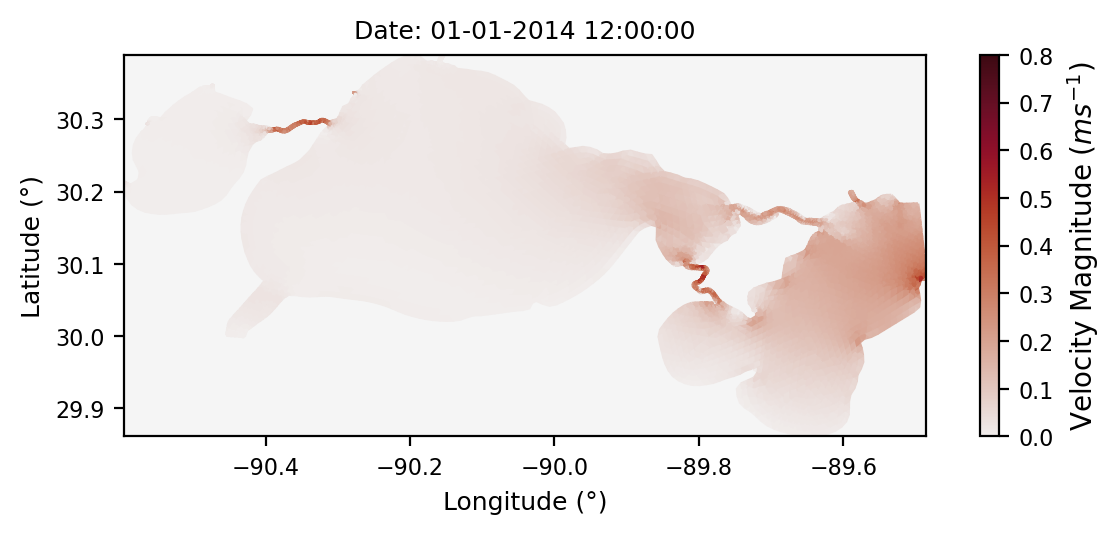

In [7]:
# Plot salinity at one timestep using the same style as the subplot.
preview_timestep = 12
t_str = time_str_all.isel(time=preview_timestep).item()
print("Plot timestamp:", t_str)

fig, ax = plt.subplots(figsize=(6.2, 2.6), dpi=200)
quad = uds_map["mesh2d_ucmag"].isel(time=preview_timestep).ugrid.plot(
    ax=ax,
    cmap=cmocean.cm.amp,
    vmin=0.0,
    vmax=0.8,
    add_colorbar=True,
    cbar_kwargs={"label": "Velocity Magnitude $(m s^{-1})$"},
)


cbar = quad.colorbar
cbar.ax.tick_params(labelsize=8)

ax.set_title(f"Date: {t_str}", fontsize=9)
ax.set_xlabel("Longitude (°)", fontsize=9)
ax.set_ylabel("Latitude (°)", fontsize=9)
ax.set_aspect("equal")
ax.set_facecolor("whitesmoke")
ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

### 3.2 Variable Movie

Create an animation for a selected variable.

In [ ]:
# from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter

# # Choose which variable to animate: salinity, temperature, velocity, water_level
# movie_var = "temperature" # Change this to the variable you want to animate

# movie_specs = {
#     "velocity": {
#         "var_name": "mesh2d_ucmag",
#         "label": "Velocity Magnitude $(m s^{-1})$",
#         "cmap": cmocean.cm.amp,
#         "vmin": 0.0,
#         "vmax": 0.8,
#         "file_tag": "velocity",
#     },
#     "water_level": {
#         "var_name": "mesh2d_s1",
#         "label": "Water Level (m)",
#         "cmap": cmocean.cm.deep,
#         "vmin": -0.20,
#         "vmax": 1.0,
#         "file_tag": "water_level",
#     },
#     "temperature": {
#         "var_name": "mesh2d_tem1",
#         "label": "Temperature (°C)",
#         "cmap": cmocean.cm.thermal,
#         "vmin": 24.0,
#         "vmax": 34.0,
#         "file_tag": "temperature",
#     },
#     "salinity": {
#         "var_name": "mesh2d_sa1",
#         "label": "Salinity (PSU)",
#         "cmap": cmocean.cm.haline,
#         "vmin": 0.0,
#         "vmax": 18.0,
#         "file_tag": "salinity",
#     },
# }

# if movie_var not in movie_specs:
#     raise ValueError(
#         f"movie_var must be one of {list(movie_specs.keys())}, got '{movie_var}'."
#     )

# spec = movie_specs[movie_var]
# var_name = spec["var_name"]
# label = spec["label"]
# cmap = spec["cmap"]
# vmin = spec["vmin"]
# vmax = spec["vmax"]
# file_tag = spec["file_tag"]

# # Try to point Matplotlib to bundled ffmpeg if imageio-ffmpeg is installed.
# ffmpeg_ready = False
# try:
#     import imageio_ffmpeg

#     plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
#     ffmpeg_ready = True
# except Exception:
#     ffmpeg_ready = False

# # Movie settings
# start_idx = 0
# end_idx = n_timesteps - 1
# frame_step = 6          # change this to control timestep spacing between frames
# fps = 6                 # playback speed
# bitrate = 1800

# # Build frame index list using the requested stride
# frame_indices = list(range(start_idx, end_idx + 1, frame_step))
# if not frame_indices:
#     raise ValueError("No frames selected. Check start_idx/end_idx/frame_step.")

# # Output location
# video_dir = PROJECT_ROOT / "outputs" / "figures" / "2013"
# video_dir.mkdir(parents=True, exist_ok=True)
# mp4_path = video_dir / f"{file_tag}_movie_step{frame_step}_fps{fps}.mp4"
# gif_path = video_dir / f"{file_tag}_movie_step{frame_step}_fps{fps}.gif"

# # Create figure and first frame
# fig, ax = plt.subplots(figsize=(6.2, 2.6), dpi=200)
# first_idx = frame_indices[0]
# first_t = time_str_all.isel(time=first_idx).item()
# quad = uds_map[var_name].isel(time=first_idx).ugrid.plot(
#     ax=ax,
#     cmap=cmap,
#     vmin=vmin,
#     vmax=vmax,
#     add_colorbar=True,
#     cbar_kwargs={"label": label},
# )

# cbar = quad.colorbar
# cbar.set_label(label, fontsize=9)
# cbar.ax.tick_params(labelsize=8)

# ax.set_xlabel("Longitude (°)", fontsize=9)
# ax.set_ylabel("Latitude (°)", fontsize=9)
# ax.set_aspect("equal")
# ax.set_facecolor("whitesmoke")
# ax.tick_params(labelsize=8)
# ax.set_title(f"Date: {first_t}", fontsize=9)


# def update(frame_num):
#     idx = frame_indices[frame_num]
#     t_str = time_str_all.isel(time=idx).item()

#     # Remove previous mesh but keep colorbar/axes styling intact
#     if ax.collections:
#         ax.collections[0].remove()

#     uds_map[var_name].isel(time=idx).ugrid.plot(
#         ax=ax,
#         cmap=cmap,
#         vmin=vmin,
#         vmax=vmax,
#         add_colorbar=False,
#     )
#     # Re-apply labels and styling because ugrid.plot can reset axis labels to x/y.
#     ax.set_xlabel("Longitude (°)", fontsize=9)
#     ax.set_ylabel("Latitude (°)", fontsize=9)
#     ax.set_aspect("equal")
#     ax.set_facecolor("whitesmoke")
#     ax.tick_params(labelsize=8)
#     ax.set_title(f"Date: {t_str}", fontsize=9)
#     return ax.collections


# anim = FuncAnimation(
#     fig,
#     update,
#     frames=len(frame_indices),
#     interval=1000 / fps,
#     blit=False,
# )

# if ffmpeg_ready:
#     writer = FFMpegWriter(fps=fps, bitrate=bitrate)
#     anim.save(mp4_path, writer=writer)
#     saved_path = mp4_path
# else:
#     # Simple fallback when ffmpeg is unavailable.
#     writer = PillowWriter(fps=fps)
#     anim.save(gif_path, writer=writer)
#     saved_path = gif_path
#     print("ffmpeg not found. Saved GIF instead of MP4.")
#     print("Set INSTALL_NOTEBOOK_DEPS = True in Cell 3, run it once, then rerun this cell for MP4.")

# plt.close(fig)

# print(f"Saved {movie_var} movie: {saved_path}")
# print(f"Frames: {len(frame_indices)} | Step: {frame_step} timestep(s) | FPS: {fps}")

Saved temperature movie: c:\Users\hydro\Lake_Pontchartrain_Model\outputs\figures\2013\temperature_movie_step6_fps6.mp4
Frames: 517 | Step: 6 timestep(s) | FPS: 6


## 4. Optional NetCDF Export

Optional: create a smaller collaborator NetCDF with selected variables and formatted time strings.

In [ ]:
# # Create Smaller .nc File for Collaborators
# export_vars = ["mesh2d_ucmag", "mesh2d_s1", "mesh2d_tem1", "mesh2d_sa1"]

# missing_vars = [v for v in export_vars if v not in uds_map]
# if missing_vars:
#     raise KeyError(f"Missing expected variables in uds_map: {missing_vars}")

# # Keep all timesteps in the requested time window and load only needed variables.
# export_ds = uds_map[export_vars].sel(time=slice(start_time, end_time))

# # Keep numeric time for indexing/ops, add formatted string time as a dedicated variable.
# orig_time = export_ds["time"]
# time_fmt = "%m-%d-%Y %H:%M:%S"
# time_str = xr.DataArray(
#     orig_time.dt.strftime(time_fmt).to_numpy(),
#     dims=("time",),
#     coords={"time": orig_time},
#     name="time_str",
# )

# # Add explicit timestep index alongside timestamps.
# export_ds = export_ds.assign_coords(
#     timestep=("time", np.arange(export_ds.sizes["time"], dtype=np.int32))
# )
# export_ds["timestep"].attrs.update(
#     {
#         "long_name": "zero_based_timestep_index_within_export_window",
#         "units": "1",
#     }
# )

# # Include formatted time strings in the file for plotting.
# export_ds["time_str"] = time_str
# export_ds["time_str"].attrs.update(
#     {
#         "long_name": "time_string",
#         "format": time_fmt,
#     }
# )

# output_dir = PROJECT_ROOT / "outputs" / "shared"
# output_dir.mkdir(parents=True, exist_ok=True)

# # Write to a UGRID-specific filename to avoid lock/overwrite issues with older exports.
# output_nc = output_dir / f"lp_model_spatial_window_{start_time:%Y%m%d}_{end_time:%Y%m%d}_ugrid.nc"

# # Makes it run faster
# encoding = {
#     var_name: {"zlib": True, "complevel": 1, "shuffle": True}
#     for var_name in export_ds.data_vars
#     if export_ds[var_name].dtype.kind in "fiu"
# }
# export_ds.ugrid.to_netcdf(output_nc, encoding=encoding)

# print(f"Wrote: {output_nc}")
# print(f"Variables: {list(export_ds.data_vars)}")
# print(f"Time range: {orig_time.min().values} to {orig_time.max().values}")
# print(f"Timesteps: {export_ds.sizes['time']}")